# SEMTM0009 Week 5: computational solutions

This is the Week 5 lab notebook with every `# TODO` filled in, and with its
outputs shown, so you can read it without running anything. **Try the
notebook yourself first.**

The written solutions (PDF, on Blackboard) explain the reasoning behind each
answer.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq, curve_fit, minimize

plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "lines.linewidth": 1.8,
                     "axes.spines.top": False, "axes.spines.right": False})

# ------------------------------------------------------------------ DATA -----
# Reads data/ next to this notebook if it is there (Jupyter, VS Code);
# otherwise, e.g. in Google Colab, fetches the same file from the course repo.
import os
DATA = ("data" if os.path.isdir("data") else
        "https://raw.githubusercontent.com/SEMTM0009-University-of-Bristol/notebooks/main/Week5/data")

d = pd.read_csv(f"{DATA}/epidemic_noisy.csv")
t = d.t_days.to_numpy(float)
y = d.I_observed.to_numpy(float)
print(f"n = {len(t)},  t from {t.min()} to {t.max()} in steps of {t[1]-t[0]}")


def rmse(residual):
    return float(np.sqrt(np.mean(np.asarray(residual)**2)))

n = 651,  t from 0.0 to 13.0 in steps of 0.02


## Look at the data before fitting anything

**Questions.** Has the epidemic peaked inside the window? Roughly how large is
the noise? Both answers change what you should do next.

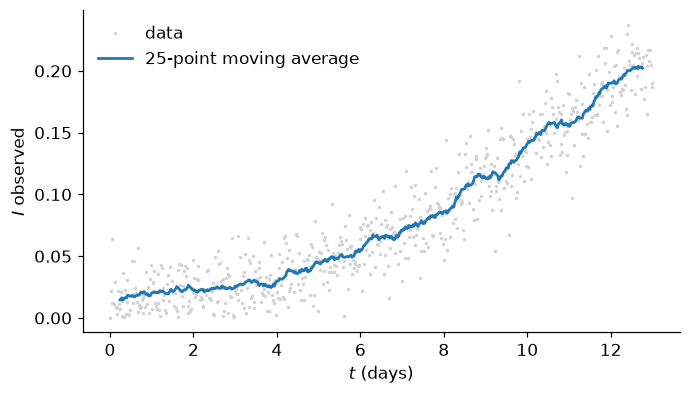

smoothed max 0.2038 at t=12.66; value at the end 0.2021
still rising at the end? True
scatter about the smooth trend: sd = 0.01812


In [2]:
k = 25
smooth = np.convolve(y, np.ones(k)/k, mode="valid")
ts = t[k//2 : k//2+len(smooth)]

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(t, y, ".", ms=2.5, color="lightgrey", label="data")
ax.plot(ts, smooth, color="tab:blue", label=f"{k}-point moving average")
ax.set(xlabel="$t$ (days)", ylabel="$I$ observed")
ax.legend(frameon=False); plt.show()

print(f"smoothed max {smooth.max():.4f} at t={ts[smooth.argmax()]:.2f}; "
      f"value at the end {smooth[-1]:.4f}")
print(f"still rising at the end? {smooth[-1] > smooth[-50]}")
print(f"scatter about the smooth trend: sd = "
      f"{np.std(y[k//2:k//2+len(smooth)] - smooth):.5f}")

*Your answer:*

---
# Question 1: fitting an exponential (about 30 min)

Fit $y=a+b\,e^{ct}$ to the data.

**(a)** First by **grid search**: take $a,b,c\in[0,1]$, put a mesh of 100 equally
spaced points on each, evaluate the RMSE at all $100^3$ combinations, and keep
the best. Report $a$, $b$, $c$ and the RMSE.

*Hint:* $\mathrm{RMSE}=\sqrt{\frac{1}{n}\sum_{i=1}^{n}\bigl(y(t_i)-I(t_i)\bigr)^2}$.
Vectorise over one parameter or this will be slow. The mesh spacing is $1/99$.

*Check:* $a=0$, $b=2/99=0.0202$, $c=18/99=0.1818$, RMSE $=0.019938$.

In [3]:
def exp_model(tt, a, b, c):
    return a + b*np.exp(c*tt)


def grid_search(t, y, n=100):
    '''Q1(a): brute force over a, b, c in [0,1], n points each.

    Vectorised over c so this takes seconds rather than minutes.  Note the mesh
    spacing: 1/(n-1).
    '''
    g = np.linspace(0, 1, n)
    E = np.exp(np.outer(g, t))            # rows indexed by c
    best = (np.inf, None)
    for a in g:
        for b in g:
            # a + b*E has shape (n, len(t)); subtracting y broadcasts along
            # the rows, so this is the RMSE for all n values of c at once.
            r = np.sqrt(np.mean((a + b*E - y)**2, axis=1))
            j = int(np.nanargmin(r)) if np.isfinite(r).any() else 0
            if np.isfinite(r[j]) and r[j] < best[0]:
                best = (float(r[j]), (a, b, g[j]))
    return best

rg, pg = grid_search(t, y)
print(f"grid: a={pg[0] if pg else np.nan}, b={pg[1] if pg else np.nan}, "
      f"c={pg[2] if pg else np.nan}")
print(f"      RMSE = {rg}")
if pg:
    print(f"\nmesh spacing = 1/99 = {1/99:.10f}")
    print(f"is b a grid point? {pg[1]:.16f}  = {round(pg[1]*99)}/99")
    print(f"is c a grid point? {pg[2]:.16f}  = {round(pg[2]*99)}/99")

grid: a=0.0, b=0.020202020202020204, c=0.18181818181818182
      RMSE = 0.01993830657983222

mesh spacing = 1/99 = 0.0101010101
is b a grid point? 0.0202020202020202  = 2/99
is c a grid point? 0.1818181818181818  = 18/99


**(b)** Now fit the same model by **least squares**
(`scipy.optimize.curve_fit`), with no box. Report the parameters and the RMSE,
and compare with (a).

*Check:* $a=-0.0253$, $b=0.0341$, $c=0.1524$, RMSE $=0.018886$: better than the
grid's, and $a$ is negative.

In [4]:
# Q1(b): the same model by least squares, with no box
p_exp, cov_exp = curve_fit(exp_model, t, y, p0=[0, 0.02, 0.18], maxfev=60000)
r_exp = rmse(exp_model(t, *p_exp) - y)
print(f"curve_fit: a={p_exp[0]:.5f}, b={p_exp[1]:.5f}, c={p_exp[2]:.5f}")
print(f"           RMSE = {r_exp:.6f}")
if np.isfinite(rg):
    print(f"\ngrid RMSE {rg:.6f}  vs  least squares {r_exp:.6f}")
    print(f"the grid is {100*(rg/r_exp-1):.1f}% worse, after 1e6 evaluations")
print(f"\nand note a = {p_exp[0]:.5f}: outside the grid's box entirely")

curve_fit: a=-0.02530, b=0.03406, c=0.15242
           RMSE = 0.018886

grid RMSE 0.019938  vs  least squares 0.018886
the grid is 5.6% worse, after 1e6 evaluations

and note a = -0.02530: outside the grid's box entirely


**Question 1(c).** Look back at (a). To how many significant figures is it
meaningful to quote those values? Is $a=0$ a fitted value or a symptom? And the
grid used $10^6$ evaluations and lost: why?

*Your answer:*

---
# Question 2: fitting a polynomial (about 30 min)

**(a)** Fit a quadratic $g(t)=p_0+p_1t+p_2t^2$ by solving the normal equations,
and report the coefficients and the RMSE.

*Hint:* $X=(A^\top A)^{-1}A^\top b$ with $A$ the Vandermonde matrix. In practice
use `numpy.linalg.lstsq`, which is better conditioned than forming
$(A^\top A)^{-1}$.

*Check:* $p_0=0.017769$, $p_1=-0.00098679$, $p_2=0.00125705$, RMSE $=0.018448$.

In [5]:
def poly_fit(t, y, degree):
    '''Linear least squares for a polynomial. Returns coefficients, low order first.

    Use numpy.linalg.lstsq rather than forming (A^T A)^{-1}, which squares the
    condition number.
    '''
    A = np.vstack([t**k for k in range(degree+1)]).T
    return np.linalg.lstsq(A, y, rcond=None)[0]


def poly_eval(coeffs, t):
    return sum(c * t**k for k, c in enumerate(coeffs))

p2 = poly_fit(t, y, 2)
print(f"quadratic: p0={p2[0]}, p1={p2[1]}, p2={p2[2]}")
print(f"           RMSE = {rmse(poly_eval(p2, t) - y)}")

quadratic: p0=0.01776939885137806, p1=-0.000986789228683923, p2=0.0012570511155893653
           RMSE = 0.018447997498586888


**(b) Choose the degree.** Split the data at random into a training set (400
points) and a held-out set (the other 251). Fit degrees 1 to 12 on the training
set only, and plot the training RMSE and the held-out RMSE against the degree.

*Check:* training error falls with every degree; held-out error is lowest at
degree 4.

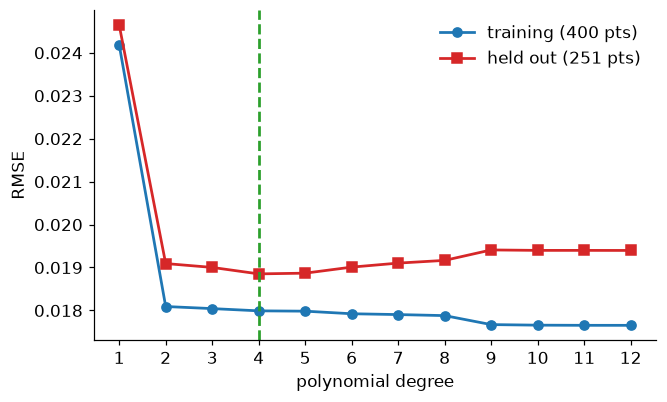

held-out error is minimised at degree 4
training error at degree 1 and 12: 0.02418 -> 0.01765


In [6]:
# Q2(b): choosing the degree with held-out data
rng = np.random.default_rng(0)
idx = rng.permutation(len(t))
train, test = idx[:400], idx[400:]

degs = np.arange(1, 13)
u = t/t.max()   # t rescaled to [0,1]. Unscaled, t**12 is about 2e13 and the
                # degree-12 fit loses so many digits that its training error rises.
tr_err, te_err = [], []
for dg in degs:
    c = poly_fit(u[train], y[train], dg)          # your function from Q2(a)
    tr_err.append(rmse(poly_eval(c, u[train]) - y[train]))
    te_err.append(rmse(poly_eval(c, u[test]) - y[test]))
tr_err, te_err = np.array(tr_err), np.array(te_err)

if np.all(np.isnan(te_err)):
    print("fill in poly_fit in Q2(a) first")
else:
    fig, ax = plt.subplots(figsize=(6.6, 3.9))
    ax.plot(degs, tr_err, "o-", color="tab:blue", label="training (400 pts)")
    ax.plot(degs, te_err, "s-", color="tab:red", label="held out (251 pts)")
    ax.axvline(degs[np.nanargmin(te_err)], color="tab:green", ls="--")
    ax.set(xlabel="polynomial degree", ylabel="RMSE", xticks=degs)
    ax.legend(frameon=False); plt.show()
    print(f"held-out error is minimised at degree {degs[np.nanargmin(te_err)]}")
    print(f"training error at degree 1 and 12: {tr_err[0]:.5f} -> {tr_err[-1]:.5f}")


**Question 2(b).** Which degree minimises the held-out error? Why must the
training error keep falling, and could it ever rise?

*Your answer:*

---
# Question 3: fitting the SIR model (about 45 min)

**(a) Frequentist.** Fit the SIR model to the data by least squares, treating
$\beta$, $\gamma$ and $I(0)$ as unknowns. Report the parameters, the RMSE and
$R_0=\beta/\gamma$.

*Hint:* integrate the ODEs inside the function you fit: for a trial
$(\beta,\gamma,I_0)$, solve the system and return $I(t)$. Pass that straight to
`curve_fit`. Use $S(0)=1-I_0$.

*Check:* $\beta=0.457$, $\gamma=0.171$, $I_0=1.14\times10^{-2}$, RMSE $=0.018402$,
$R_0=2.67$.

In [7]:
def sir_I(tt, beta, gamma, I0):
    '''I(t) from the SIR model with S(0) = 1 - I0.'''
    s = solve_ivp(lambda _, z: [-beta*z[0]*z[1], beta*z[0]*z[1] - gamma*z[1]],
                  [0, float(np.max(tt))], [1-I0, I0],
                  dense_output=True, rtol=1e-10, atol=1e-14)
    return s.sol(tt)[1]

p_sir, cov_sir = curve_fit(sir_I, t, y, p0=[1.0, 0.3, 1e-3], maxfev=30000)
r_sir = rmse(sir_I(t, *p_sir) - y)
beta_hat, gamma_hat, I0_hat = p_sir
print(f"SIR fit: beta={beta_hat:.4f}, gamma={gamma_hat:.4f}, I0={I0_hat:.3e}")
print(f"         RMSE = {r_sir:.6f}")
print(f"         R0 = beta/gamma = {beta_hat/gamma_hat:.4f}")
print(f"         r  = beta-gamma = {beta_hat-gamma_hat:.4f} /day")


SIR fit: beta=0.4568, gamma=0.1708, I0=1.140e-02
         RMSE = 0.018402
         R0 = beta/gamma = 2.6743
         r  = beta-gamma = 0.2860 /day


**(b) Frequentist uncertainty: the profile likelihood of $R_0$.** Fix $R_0$ at a
value, write $\beta=R_0\gamma$, re-optimise $\gamma$ and $I_0$, and record the best
RMSE. Repeat over $R_0\in[2.2,3.4]$. Plot the deviance and read off the 95%
confidence interval for $R_0$.

*Hint:* with Gaussian noise and $\sigma$ estimated from the residuals,
$2(\hat\ell-\ell_p)=2n\log(\mathrm{RMSE}_p/\mathrm{RMSE}_{\min})$, and the 95%
interval is where this is at most 3.84. The code finds the two edges by
root-finding; you write the re-optimisation.

*Check:* 95% confidence interval $2.47$ to $3.07$.

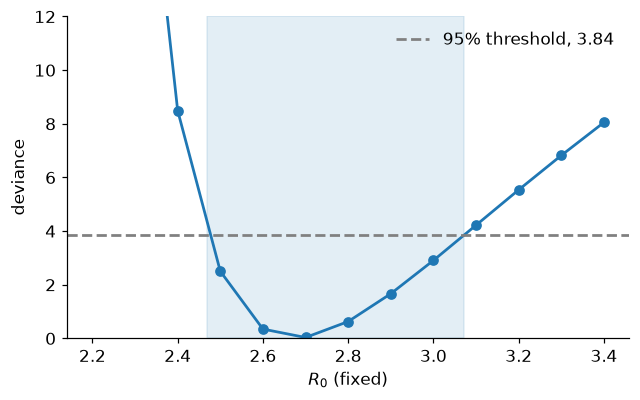

R0 = 2.674, 95% confidence interval 2.468 to 3.071


In [8]:
def profile_R0(R0):
    '''Best RMSE with R0 fixed: beta = R0*gamma, re-optimise gamma and I0.'''
    res = minimize(lambda z: rmse(sir_I(t, R0*z[0], z[0], z[1]) - y),
                   [gamma_hat, I0_hat], method="Nelder-Mead",
                   options=dict(xatol=1e-7, fatol=1e-11, maxiter=3000))
    return res.fun

n = len(t)
def deviance(R0):
    return 2*n*np.log(profile_R0(R0)/r_sir)

R0_grid = np.linspace(2.2, 3.4, 13)
dev = np.array([deviance(R) for R in R0_grid])

if np.all(np.isnan(dev)):
    print("fill in profile_R0 first")
else:
    R0_hat = beta_hat/gamma_hat
    ci_lo = brentq(lambda R: deviance(R) - 3.84, R0_grid[0], R0_hat, xtol=1e-3)
    ci_hi = brentq(lambda R: deviance(R) - 3.84, R0_hat, R0_grid[-1], xtol=1e-3)
    fig, ax = plt.subplots(figsize=(6.6, 3.8))
    ax.plot(R0_grid, dev, "o-", color="tab:blue")
    ax.axhline(3.84, color="grey", ls="--", label="95% threshold, 3.84")
    ax.axvspan(ci_lo, ci_hi, color="tab:blue", alpha=0.12)
    ax.set(xlabel=r"$R_0$ (fixed)", ylabel="deviance", ylim=(0, 12))
    ax.legend(frameon=False); plt.show()
    print(f"R0 = {R0_hat:.3f}, 95% confidence interval {ci_lo:.3f} to {ci_hi:.3f}")


**(c) Bayesian.** Use a Gaussian likelihood with $\sigma$ equal to the RMSE from
(a), and uniform priors $\beta\in(0,2)$, $\gamma\in(0,1)$, $I_0\in(0,0.1)$. Sample
the posterior by random-walk Metropolis: 5000 steps, discarding the first 1000.
Run three chains from different starting points and check that they agree.
Report the posterior median and 95% credible interval of $\beta$, $\gamma$ and
$R_0$.

*Hint:* the proposal is shaped by the covariance matrix returned by `curve_fit`
in (a), so that steps follow the narrow ridge in $(\beta,\gamma)$. You write the
acceptance step.

*Check:* about 30% of proposals accepted; $R_0$ median $2.68$, 95% interval
$2.47$ to $3.07$.

chain 1: accepted 31%, R0 median 2.685
chain 2: accepted 30%, R0 median 2.680
chain 3: accepted 32%, R0 median 2.684
beta   median 0.455   95% interval 0.393 to 0.513
gamma  median 0.170   95% interval 0.128 to 0.207
R0     median 2.683   95% interval 2.471 to 3.073


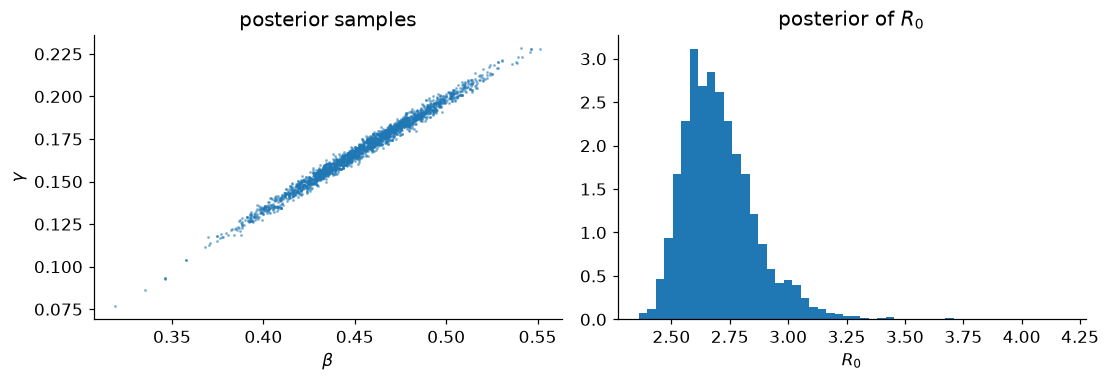

In [9]:
sigma = r_sir

def log_post(theta):
    '''Log posterior, up to a constant: Gaussian likelihood times uniform priors.'''
    beta, gamma, I0 = theta
    if not (0 < beta < 2 and 0 < gamma < 1 and 0 < I0 < 0.1):
        return -np.inf                                  # outside the prior
    res = sir_I(t, beta, gamma, I0) - y
    return -0.5*np.sum(res**2)/sigma**2


L = np.linalg.cholesky(cov_sir)        # proposal shape, from the fit in (a)
step = 2.38/np.sqrt(3)

def metropolis(start, n_steps=5000, burn=1000, seed=0):
    rng = np.random.default_rng(seed)
    theta = np.array(start, float); lp = log_post(theta)
    chain, accepted = [], 0
    for _ in range(n_steps):
        prop = theta + step*(L @ rng.standard_normal(3))
        lp_prop = log_post(prop)
        # alpha = posterior(prop)/posterior(theta); P(y) cancels in the ratio
        log_alpha = lp_prop - lp
        if np.log(rng.uniform()) < log_alpha:
            theta, lp = prop, lp_prop
            accepted += 1
        chain.append(theta.copy())        # recorded whether accepted or not
    return np.array(chain[burn:]), accepted/n_steps

starts = [p_sir, [0.40, 0.13, 0.02], [0.52, 0.21, 0.007]]
chains = [metropolis(s0, seed=k) for k, s0 in enumerate(starts, 1)]
for k, (ch, acc) in enumerate(chains, 1):
    R0s = ch[:, 0]/ch[:, 1]
    print(f"chain {k}: accepted {acc:.0%}, R0 median {np.median(R0s):.3f}")

samples = np.vstack([ch for ch, _ in chains])
for name, v in [("beta", samples[:, 0]), ("gamma", samples[:, 1]),
                ("R0", samples[:, 0]/samples[:, 1])]:
    lo, med, hi = np.percentile(v, [2.5, 50, 97.5])
    print(f"{name:6s} median {med:.3f}   95% interval {lo:.3f} to {hi:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(samples[::5, 0], samples[::5, 1], ".", ms=2, alpha=0.4)
ax[0].set(xlabel=r"$\beta$", ylabel=r"$\gamma$", title="posterior samples")
ax[1].hist(samples[:, 0]/samples[:, 1], bins=50, density=True)
ax[1].set(xlabel=r"$R_0$", title="posterior of $R_0$")
plt.tight_layout(); plt.show()


**Question 3(d).** Compare the frequentist and the Bayesian answers for $R_0$: the
point estimates and the two intervals. Why are they so close here, and when would
you expect them to differ?

*Your answer:*

---
# Question 4: what do the fits tell you? (about 15 min)

Write about 150 words to the modeller who gave you the data. Say what you
fitted, which fit you would use and why, and what the fits tell you about the
disease: has the epidemic peaked within the window, how fast is it growing, and
what is $R_0$? Give each number with its uncertainty, and only to the precision it
deserves.

*Your report:*